# Desafio 1 — Análise de Crédito (CredAIR)


## Dicionário de dados


| Coluna               | Descrição                                                               |
| -------------------- | ----------------------------------------------------------------------- |
| `idade`              | Idade do solicitante no momento da proposta                             |
| `estado`             | Estado de residência do solicitante                                     |
| `escolaridade`       | Nível de escolaridade declarado pelo solicitante                        |
| `renda_mensal`       | Renda mensal declarada pelo solicitante, em reais                       |
| `tempo_emprego_anos` | Tempo, em anos, no emprego atual                                        |
| `score_credito`      | Pontuação utilizada para representar o perfil de crédito do solicitante |
| `valor_solicitado`   | Valor solicitado no empréstimo, em reais                                |
| `prazo_meses`        | Prazo solicitado para pagamento do empréstimo, em meses                 |
| `finalidade`         | Principal finalidade informada para o empréstimo                        |
| `dividas_ativas`     | Quantidade de dívidas atualmente em aberto                              |
| `inadimplente`       | Indica se a proposta resultou em inadimplência                          |

Os dados representam os **registros recebidos pela equipe de dados** e devem ser analisados antes de qualquer decisão sobre sua utilização na modelagem.

## Importando bibliotecas

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from dotenv import load_dotenv

load_dotenv()

RANDOM_STATE = 108
path_data = os.environ.get("PATH_DATA")

In [66]:
data = pd.read_csv(path_data)

In [67]:
data

,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,2911.82,14,690,5934.19,60,Viagem,1,0
1,49,RR,Ensino Médio,3176.43,5,676,6791.38,24,Outros,2,0
2,48,AL,Ensino Superior,3429.40,23,558,14666.78,24,Outros,5,1
3,59,GO,Ensino Fundamental,10096.70,2,739,19053.24,24,Reforma,0,0
4,37,RJ,Ensino Fundamental,3033.25,24,797,6171.31,6,Educação,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4995,31,PB,Ensino Médio,3374.04,8,677,10198.45,24,Outros,2,0
4996,64,AM,Ensino Superior,3638.91,20,643,15374.40,24,Reforma,1,0
4997,48,MT,Ensino Médio,2211.31,21,486,8236.10,48,Saúde,0,1
4998,19,AP,Ensino Superior,14709.61,4,766,10617.90,18,Veículo,1,0


# Análise do Conjunto de dados (EDA)

In [68]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idade               5000 non-null   int64  
 1   estado              5000 non-null   str    
 2   escolaridade        5000 non-null   str    
 3   renda_mensal        5000 non-null   float64
 4   tempo_emprego_anos  5000 non-null   int64  
 5   score_credito       5000 non-null   int64  
 6   valor_solicitado    5000 non-null   float64
 7   prazo_meses         5000 non-null   int64  
 8   finalidade          5000 non-null   str    
 9   dividas_ativas      5000 non-null   int64  
 10  inadimplente        5000 non-null   int64  
dtypes: float64(2), int64(6), str(3)
memory usage: 429.8 KB


In [69]:
cat_columns = data.select_dtypes(include="str").columns.tolist()
num_columns = data.select_dtypes(include="number").columns.tolist()

In [70]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
idade,5000.0,47.77,31.65,18.00,32.00,46.00,61.00,750.00
renda_mensal,5000.0,5228.63,3968.48,100.00,2697.32,4146.30,6458.88,44814.19
tempo_emprego_anos,5000.0,12.66,7.52,1.00,6.00,13.00,19.00,74.00
score_credito,5000.0,652.48,84.82,335.00,594.00,653.00,710.00,850.00
valor_solicitado,5000.0,14264.66,8268.26,1721.48,8467.17,12365.63,17764.88,50000.00
prazo_meses,5000.0,29.92,15.48,6.00,18.00,24.00,36.00,60.00
dividas_ativas,5000.0,1.90,1.86,0.00,0.00,1.00,3.00,7.00
inadimplente,5000.0,0.34,0.48,0.00,0.00,0.00,1.00,1.00


Já aparecem sinais de inconsistência: `idade` com máximo em 750, `renda_mensal` com mínimo de R$ 100 e `tempo_emprego_anos` com máximo de 74 anos. Vamos olhar com mais cuidado.

In [71]:
for v in cat_columns:
    print(f"Valores distintos de '{v}':", data[v].nunique())
    print(sorted(data[v].unique()))
    print()

Valores distintos de 'estado': 85
['  AC ', '  AL ', '  AL  ', '  AM ', '  CE ', '  DF ', '  GO ', '  MG ', '  MS ', '  PA ', '  PB ', '  PB  ', '  PE  ', '  PI ', '  RO  ', '  RR ', '  RR  ', '  RS ', '  RS  ', '  SE ', '  SE  ', '  SP ', '  SP  ', ' AC  ', ' AL ', ' AM ', ' AM  ', ' AP  ', ' BA ', ' CE ', ' DF ', ' ES ', ' GO ', ' GO  ', ' MA ', ' MG ', ' MG  ', ' MS ', ' MT  ', ' PA ', ' PB ', ' PB  ', ' PE ', ' PE  ', ' PI ', ' PI  ', ' RJ ', ' RJ  ', ' RN ', ' RN  ', ' RO ', ' RR ', ' RR  ', ' SC ', ' SC  ', ' SE ', ' SE  ', ' TO ', 'AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']

Valores distintos de 'escolaridade': 4
['Ensino Fundamental', 'Ensino Médio', 'Ensino Superior', 'Pós-graduação']

Valores distintos de 'finalidade': 6
['Educação', 'Outros', 'Reforma', 'Saúde', 'Veículo', 'Viagem']



In [72]:
for v in num_columns:
    print(f"Valor máximo de '{v}':", data[v].max())
    print(f"Valor mínimo de '{v}':", data[v].min())
    print()

Valor máximo de 'idade': 750
Valor mínimo de 'idade': 18

Valor máximo de 'renda_mensal': 44814.19
Valor mínimo de 'renda_mensal': 100.0

Valor máximo de 'tempo_emprego_anos': 74
Valor mínimo de 'tempo_emprego_anos': 1

Valor máximo de 'score_credito': 850
Valor mínimo de 'score_credito': 335

Valor máximo de 'valor_solicitado': 50000.0
Valor mínimo de 'valor_solicitado': 1721.48

Valor máximo de 'prazo_meses': 60
Valor mínimo de 'prazo_meses': 6

Valor máximo de 'dividas_ativas': 7
Valor mínimo de 'dividas_ativas': 0

Valor máximo de 'inadimplente': 1
Valor mínimo de 'inadimplente': 0



In [73]:
print("Nulos por coluna:"); print(data.isna().sum()); print()
print("Linhas duplicadas:", data.duplicated().sum())

Nulos por coluna:
idade                 0
estado                0
escolaridade          0
renda_mensal          0
tempo_emprego_anos    0
score_credito         0
valor_solicitado      0
prazo_meses           0
finalidade            0
dividas_ativas        0
inadimplente          0
dtype: int64

Linhas duplicadas: 19


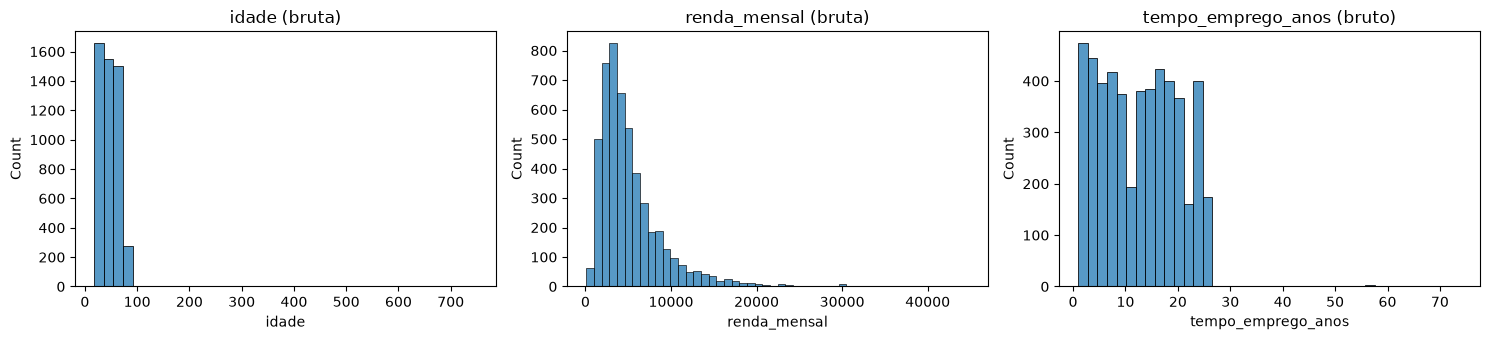

idade > 100: [210, 280, 300, 340, 360, 430, 440, 500, 540, 660, 670, 680, 700, 710, 750]
tempo_emprego > idade: 8 linhas
renda < 600: [100.0, 150.0, 200.0, 250.0, 300.0, 350.0, 400.0, 450.0, 500.0, 550.0]


In [74]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(data["idade"], bins=40, ax=ax[0]); ax[0].set_title("idade (bruta)")
sns.histplot(data["renda_mensal"], bins=50, ax=ax[1]); ax[1].set_title("renda_mensal (bruta)")
sns.histplot(data["tempo_emprego_anos"], bins=40, ax=ax[2]); ax[2].set_title("tempo_emprego_anos (bruto)")
plt.tight_layout(); plt.show()

print("idade > 100:", sorted(data.loc[data["idade"] > 100, "idade"].tolist()))
print("tempo_emprego > idade:", (data["tempo_emprego_anos"] > data["idade"]).sum(), "linhas")
print("renda < 600:", sorted(data.loc[data["renda_mensal"] < 600, "renda_mensal"].tolist()))

**Observações:**
- `estado` tem espaços sobrando em quantidades variadas (por exemplo `'  DF '`), o que gera **85 valores distintos** para apenas 27 UFs.
- `idade` tem valores extremos não condizentes a idades humanas. Os 15 valores acima de 100 (660, 680, 710, ...). *Possível erro de digitação.
- `tempo_emprego_anos` maior que a idade.
- `renda_mensal` tem poucos valores muito baixos (R$ 100 a R$ 550, de 50 em 50), que destoam do restante.
- Há linhas duplicadas.

,qtd,proporção
inadimplente,,
0,3280,0.656
1,1720,0.344


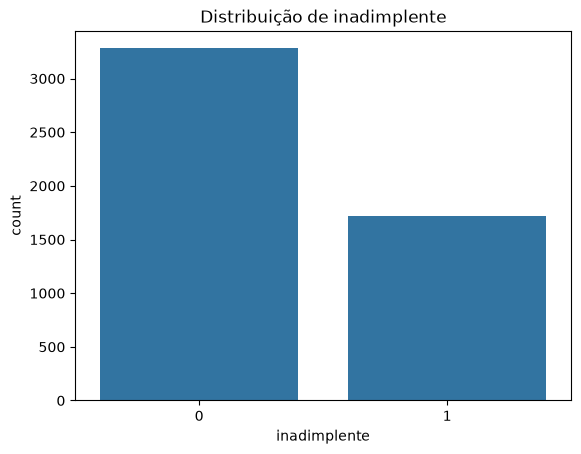

In [75]:
cont = data["inadimplente"].value_counts()
prop = data["inadimplente"].value_counts(normalize=True).round(3)
display(pd.DataFrame({"qtd": cont, "proporção": prop}))
ax = sns.countplot(x="inadimplente", data=data); ax.set_title("Distribuição de inadimplente")
plt.show()

Observações:

- Aproximadamente **34%** das propostas são inadimplentes. 

O desbalanceamento é **moderado**: a classe positiva é minoritária.

## Análise de Outliers

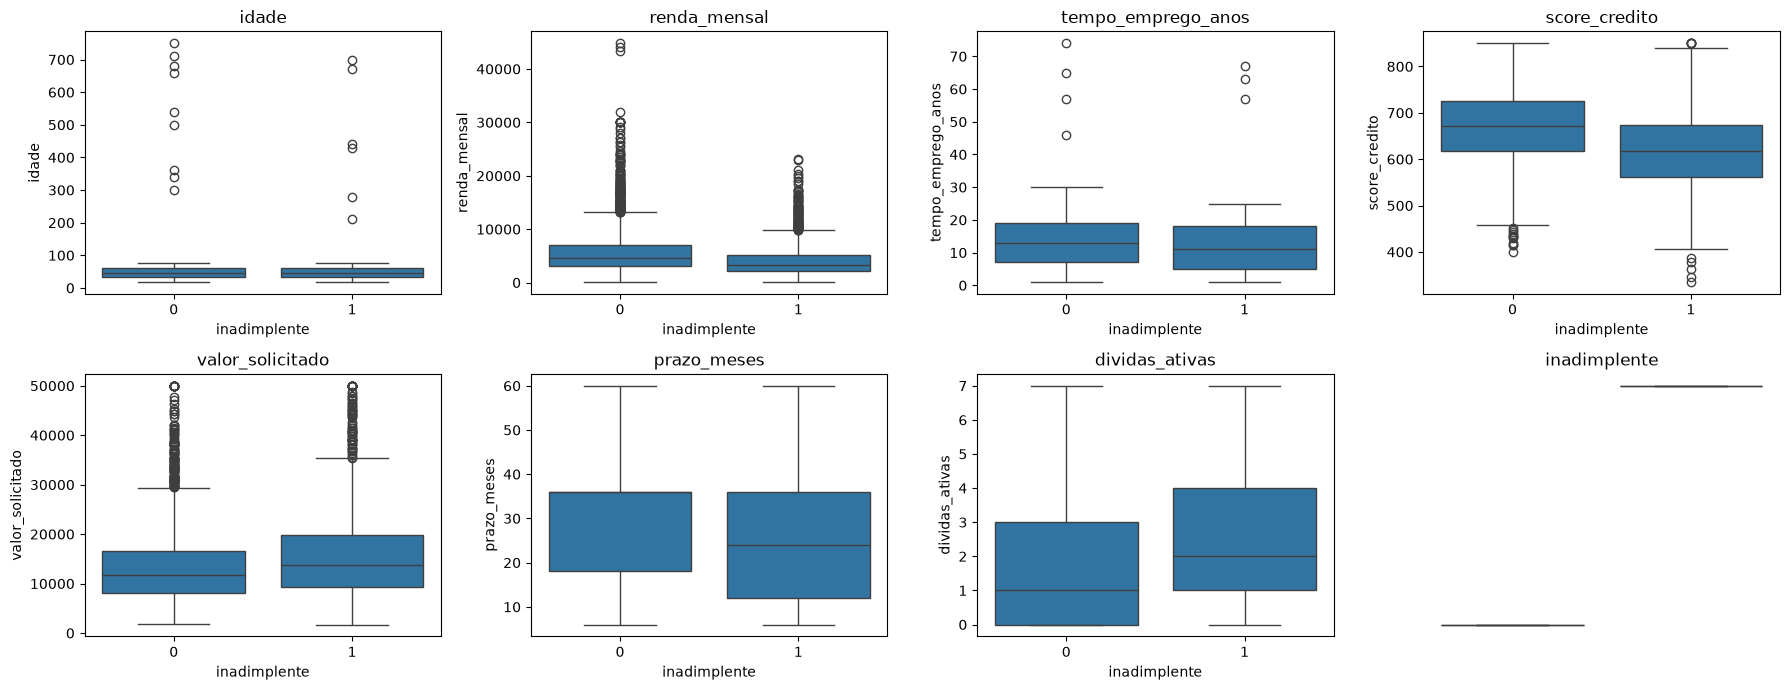

In [76]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_columns):
    sns.boxplot(x="inadimplente", y=c, data=data, ax=ax); ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

inadimplente,0,1
escolaridade,,
Ensino Fundamental,67.64,32.36
Ensino Médio,64.05,35.95
Ensino Superior,66.62,33.38
Pós-graduação,66.27,33.73


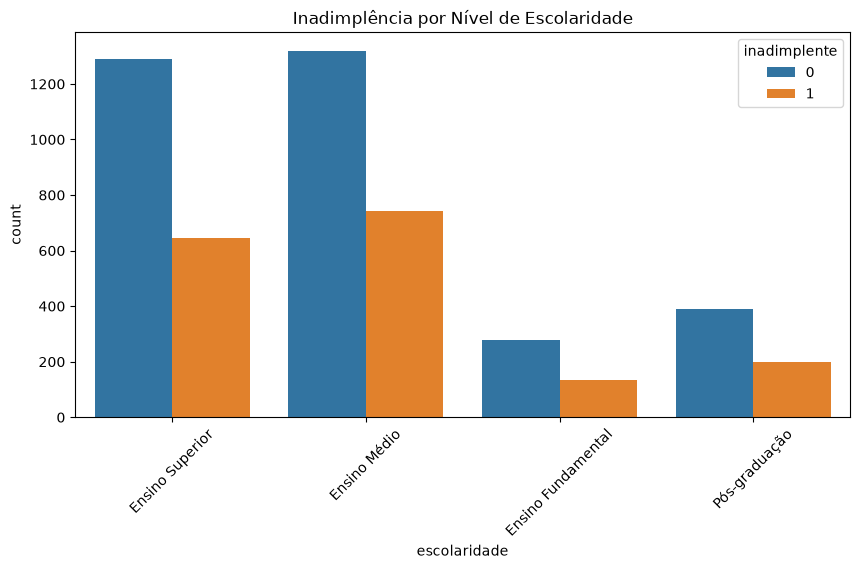

In [77]:
# Tabela cruzada mostrando o percentual de inadimplência dentro de cada categoria
tabela_cruzada_escolaridade_inadimplente = pd.crosstab(data['escolaridade'], data['inadimplente'], normalize='index') * 100
display(tabela_cruzada_escolaridade_inadimplente.round(2))

# Visualização do cruzamento
plt.figure(figsize=(10, 5))
sns.countplot(data=data, x='escolaridade', hue='inadimplente')
plt.title('Inadimplência por Nível de Escolaridade')
plt.xticks(rotation=45)
plt.show()

inadimplente,0,1
estado,,
AC,100.00,0.00
AL,50.00,50.00
AL,50.00,50.00
AM,100.00,0.00
CE,0.00,100.00
...,...,...
RS,58.56,41.44
SC,67.01,32.99
SE,65.00,35.00


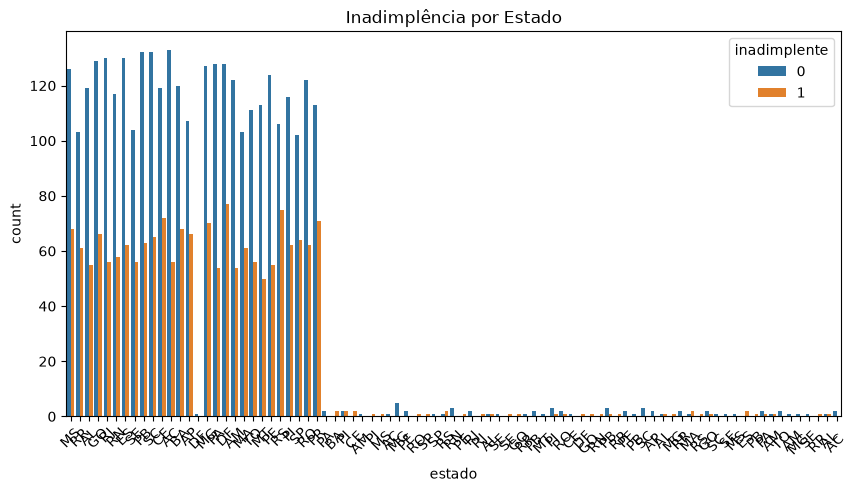

In [78]:
# Tabela cruzada mostrando o percentual de inadimplência dentro de cada categoria
tabela_cruzada_estado_inadimplente = pd.crosstab(data['estado'], data['inadimplente'], normalize='index') * 100
display(tabela_cruzada_estado_inadimplente.round(2))

# Visualização do cruzamento
plt.figure(figsize=(10, 5))
sns.countplot(data=data, x='estado', hue='inadimplente')
plt.title('Inadimplência por Estado')
plt.xticks(rotation=45)
plt.show()

inadimplente,0,1
finalidade,,
Educação,66.71,33.29
Outros,66.31,33.69
Reforma,65.09,34.91
Saúde,62.68,37.32
Veículo,65.51,34.49
Viagem,67.61,32.39


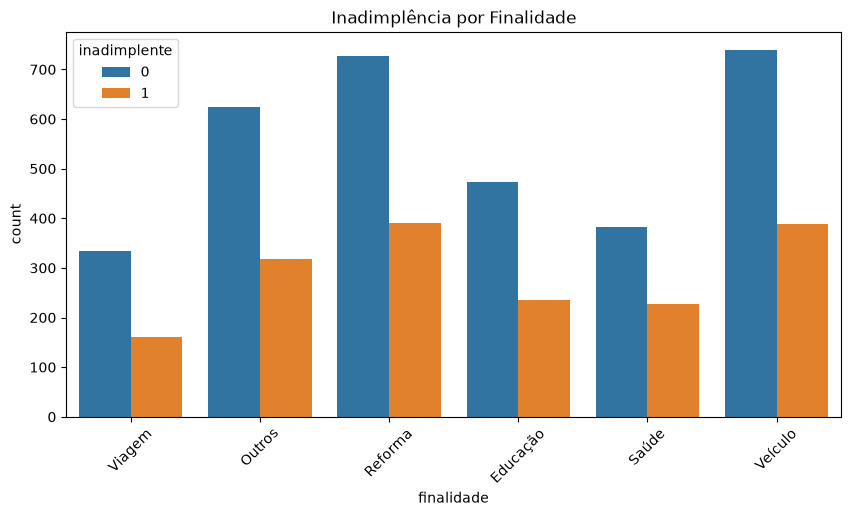

In [79]:
# Tabela cruzada mostrando o percentual de inadimplência dentro de cada categoria
tabela_cruzada_finalidade_inadimplente = pd.crosstab(data['finalidade'], data['inadimplente'], normalize='index') * 100
display(tabela_cruzada_finalidade_inadimplente.round(2))

# Visualização do cruzamento
plt.figure(figsize=(10, 5))
sns.countplot(data=data, x='finalidade', hue='inadimplente')
plt.title('Inadimplência por Finalidade')
plt.xticks(rotation=45)
plt.show()

# Limpeza dos dados

In [80]:
# 1) estado
data["estado"] = data["estado"].str.strip().str.upper()

# 2) duplicatas (após padronizar texto)
data = data.drop_duplicates().reset_index(drop=True)

# 3) valores inválidos -> NaN
mask_idade = data["idade"] > 100
data.loc[mask_idade, "idade"] = np.nan
mask_tempo = data["tempo_emprego_anos"] >= (data["idade"] - 14)
data.loc[mask_tempo, "tempo_emprego_anos"] = np.nan
mask_renda = data["renda_mensal"] < 600
data.loc[mask_renda, "renda_mensal"] = np.nan

print(f"idade inválida: {mask_idade.sum()} | tempo_emprego inválido: {mask_tempo.sum()} | renda inválida: {mask_renda.sum()}")
print("Nulos após limpeza:"); print(data.isna().sum()[lambda s: s > 0])
print("Estados distintos:", data["estado"].nunique())

idade inválida: 15 | tempo_emprego inválido: 760 | renda inválida: 10
Nulos após limpeza:
idade                  15
renda_mensal           10
tempo_emprego_anos    760
dtype: int64
Estados distintos: 27


In [ ]:
def limpar_dados_credito(df_bruto):
    """
    Função que recebe o DataFrame bruto, padroniza strings,
    remove duplicatas e trata valores inconsistentes baseados
    em regras de negócio.
    """
    df = df_bruto.copy()
    n0 = len(df)
    
    # 1. Padronização de todas as Strings (Categorias)
    colunas_texto = df.select_dtypes(include=['object', 'str']).columns
    for col in colunas_texto:
        df[col] = df[col].str.strip().str.upper()


    df = df.drop_duplicates().reset_index(drop=True)
    print(f"✔️ Duplicatas removidas: {n0 - len(df)} linhas descartadas. Restam {len(df)}.")
    mask_idade = (df["idade"] > 100) | (df["idade"] < 18)
    mask_tempo = df["tempo_emprego_anos"] >= (df["idade"] - 14)     
    mask_renda = df["renda_mensal"] < 600

    # Contagem de inconsistências encontradas
    print(f"\n⚠️ Inconsistências identificadas e transformadas em NaN:")
    print(f"   - Idade irreal: {mask_idade.sum()} registros")
    print(f"   - Tempo de emprego impossível: {mask_tempo.sum()} registros")
    print(f"   - Renda muito baixa: {mask_renda.sum()} registros")

    # Aplicando os NaNs
    df.loc[mask_idade, "idade"] = np.nan
    df.loc[mask_tempo, "tempo_emprego_anos"] = np.nan
    df.loc[mask_renda, "renda_mensal"] = np.nan
    
    linhas_antes_dropna = len(df)
    df = df.dropna().reset_index(drop=True)
    print(f"\n✔️ Linhas com inconsistências removidas (dropna): {linhas_antes_dropna - len(df)} linhas descartadas.")
    
    print(f"\n✅ Base final limpa: {len(df)} linhas e {df.shape[1]} colunas prontas para EDA.")
    
    return df

# Aplicando a função
df_limpo = limpar_dados_credito(data)

✔️ Duplicatas removidas: 0 linhas descartadas. Restam 4981.

⚠️ Inconsistências identificadas e transformadas em NaN:
   - Idade irreal: 0 registros
   - Tempo de emprego impossível: 0 registros
   - Renda muito baixa: 0 registros

✔️ Linhas com inconsistências removidas (dropna): 782 linhas descartadas.

✅ Base final limpa: 4199 linhas e 11 colunas prontas para EDA.


In [82]:
# Converte todas as colunas da lista de uma vez
df_limpo[cat_columns] = df_limpo[cat_columns].astype("category")
df_limpo["inadimplente"] = df_limpo["inadimplente"].astype(int)

,correlação de Spearman com inadimplente
score_credito,-0.302
renda_mensal,-0.228
prazo_meses,-0.115
tempo_emprego_anos,-0.091
idade,-0.063
valor_solicitado,0.138
dividas_ativas,0.162


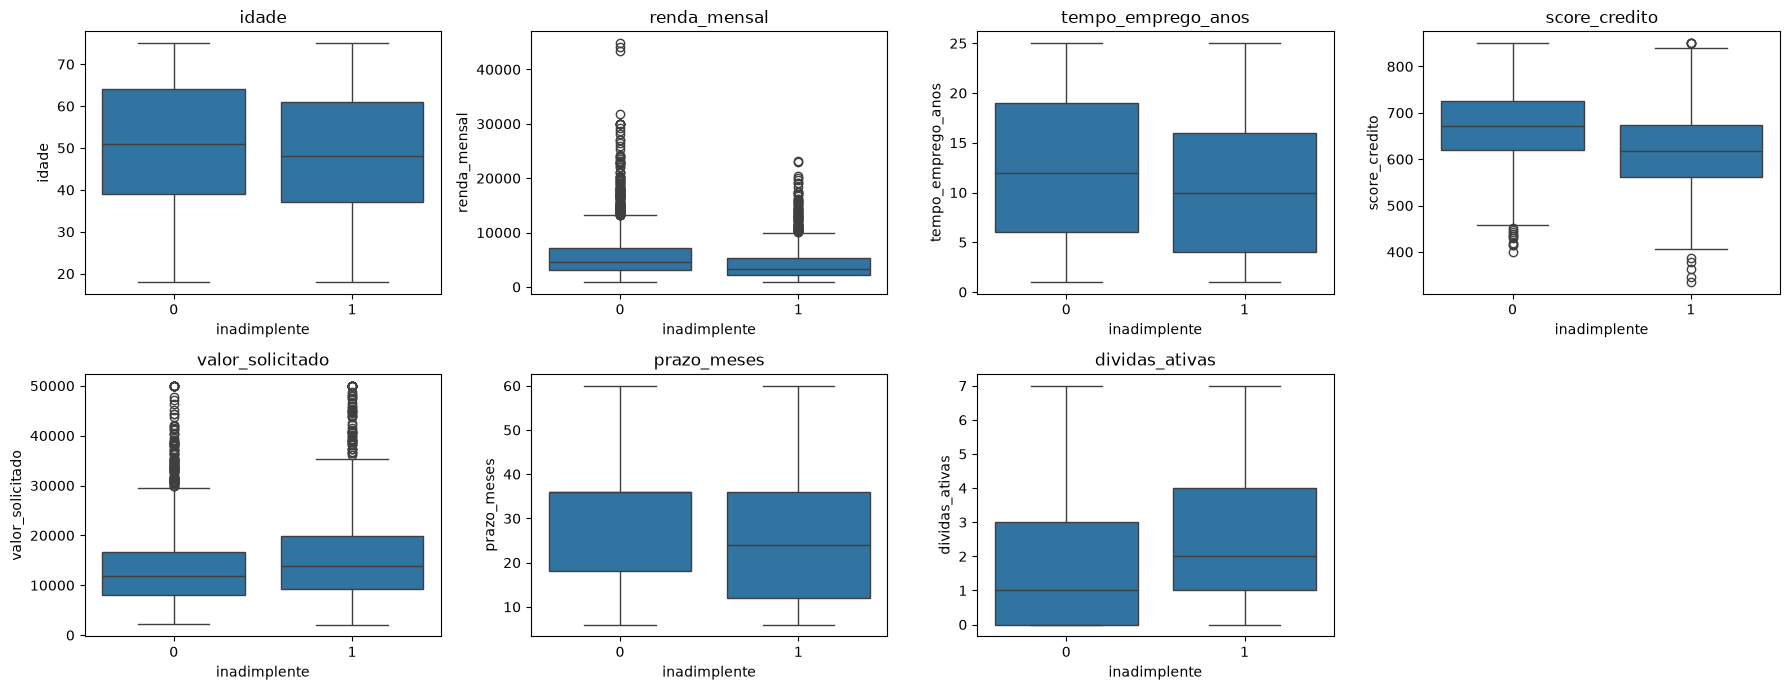

In [83]:
num_cols = ["idade", "renda_mensal", "tempo_emprego_anos", "score_credito", "valor_solicitado", "prazo_meses", "dividas_ativas"]
corr = df_limpo[num_cols + ["inadimplente"]].corr(method="spearman")["inadimplente"].drop("inadimplente").sort_values()
display(corr.round(3).to_frame("correlação de Spearman com inadimplente"))

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x="inadimplente", y=c, data=df_limpo, ax=ax); ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

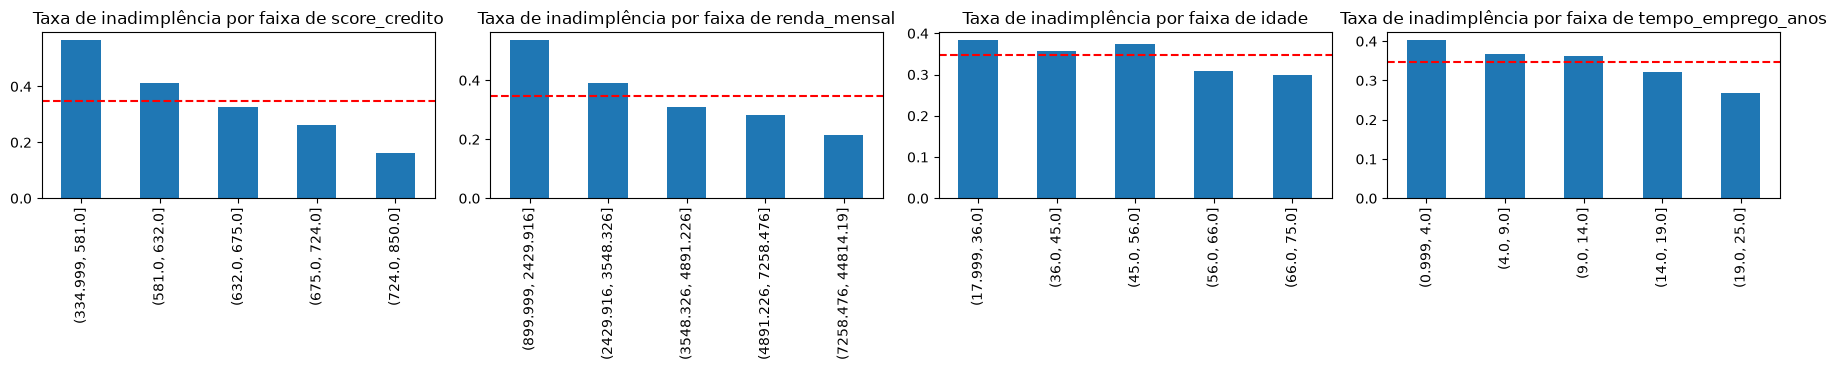

In [84]:
# Taxa de inadimplência por faixas (quintis) das variáveis numéricas contínuas
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, ["score_credito", "renda_mensal", "idade", "tempo_emprego_anos"]):
    t = df_limpo.groupby(pd.qcut(df_limpo[c], 5, duplicates="drop"))["inadimplente"].mean()
    t.plot(kind="bar", ax=ax); ax.set_title(f"Taxa de inadimplência por faixa de {c}")
    ax.set_xlabel(""); ax.axhline(df_limpo["inadimplente"].mean(), color="red", ls="--")
plt.tight_layout(); plt.show()

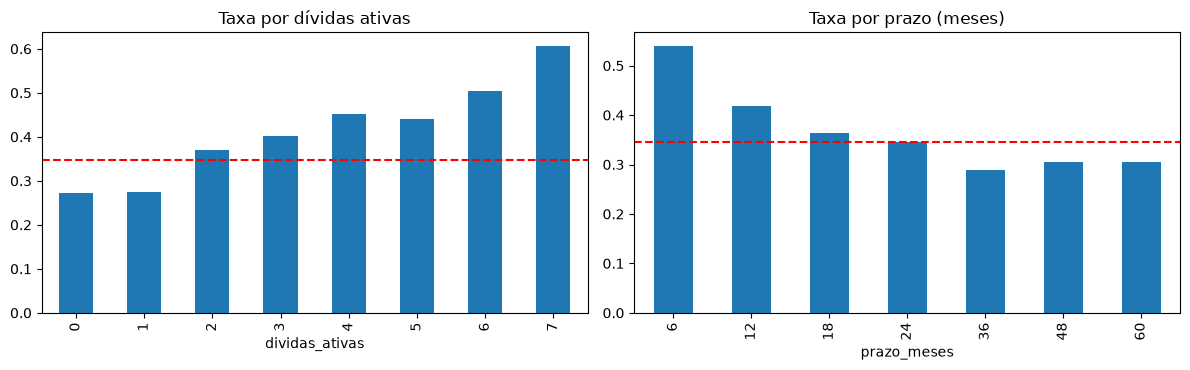

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
df_limpo.groupby("dividas_ativas")["inadimplente"].mean().plot(kind="bar", ax=axes[0], title="Taxa por dívidas ativas")
df_limpo.groupby("prazo_meses")["inadimplente"].mean().plot(kind="bar", ax=axes[1], title="Taxa por prazo (meses)")
for a in axes: a.axhline(df_limpo["inadimplente"].mean(), color="red", ls="--")
plt.tight_layout(); plt.show()

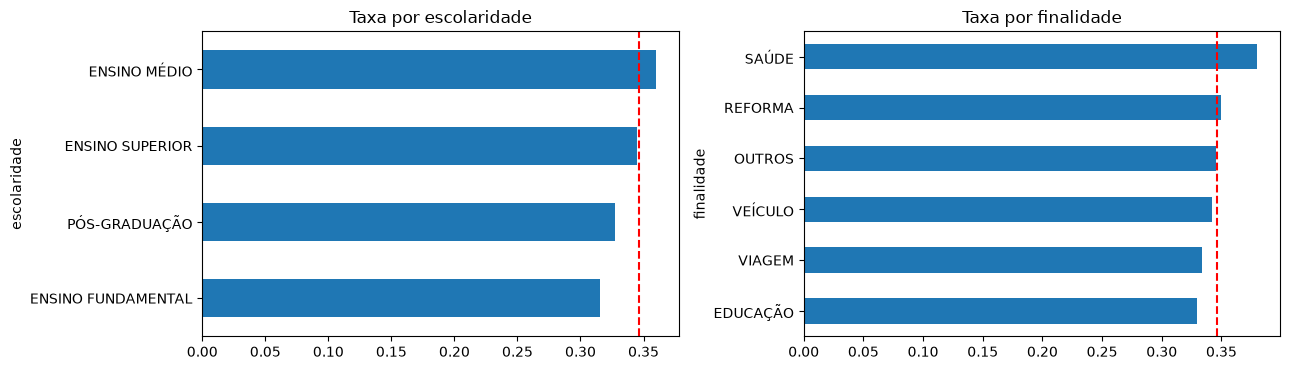

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, c in zip(axes, ["escolaridade", "finalidade"]):
    df_limpo.groupby(c, observed=True)["inadimplente"].mean().sort_values().plot(kind="barh", ax=ax, title=f"Taxa por {c}")
    ax.axvline(df_limpo["inadimplente"].mean(), color="red", ls="--")
plt.tight_layout(); plt.show()

**Observações:**
- `score_credito` é a variável numérica com a relação **mais forte**: quanto menor o score, maior a inadimplência.
- `renda_mensal` baixa e mais `dividas_ativas` também se associam a mais inadimplência.
- Prazos muito curtos (6 meses) mostram inadimplência alta. Isso é coerente com parcelas mais pesadas para o mesmo valor.
- `idade`, `escolaridade` e `finalidade` têm relação **fraca** com a variável alvo.

Isso sugere que o que importa é a **capacidade de pagamento** (renda frente ao tamanho da parcela). 

## Engenharia de atributos
